# Hallucination Detection in Foundation Models

Seminar notebook covering hallucination detection across three distinct domains:

1. **Large Language Models (LLMs):** From token logits and entropy paradoxes to black-box semantic entropy, internal probes, and mechanistic attention methods (**INTRYGUE**, **ReDeEP**, **TOHA**).
2. **Generated Video (Text-to-Video):** Detecting hallucinations directly in generated frames — prompt inconsistencies, physical violations, and spatiotemporal artifacts (**SoraDetector**, **ViBe**, **T2V-CompBench**, **PhyGenEval**, **PQSG**).
3. **Time Series Foundation Models (TSFMs):** Zero-shot forecasting hallucinations, signal subspace analysis, and test-time intervention (**Zou et al., NeurIPS 2025**).


## How to Read the Definitions

At its core, a **hallucination detector** is a scoring function:

$$\text{Decision}(y) = \begin{cases} \text{Hallucination}, & f(E, y) > \tau \\ \text{Faithful / Grounded}, & f(E, y) \le \tau \end{cases}$$

where $y$ is the generated output, $E$ is the grounding evidence, and $\tau$ is a decision threshold.

What changes fundamentally across domains is the nature of the evidence $E$:

| Setting | Generated Output $y$ | Grounding Evidence $E$ | "Supported / Faithful" Means |
| :--- | :--- | :--- | :--- |
| **LLM (Factuality)** | Generated factual claims | Real-world knowledge corpus / knowledge base | Claims match external facts about the world |
| **LLM (Faithfulness / RAG)** | Answer, summary, reasoning step | Provided context document / prompt | Generated text strictly follows the given document |
| **Generated Video (T2V)** | Video frames / pixel sequences | Text prompt, temporal tracks, physical laws | Pixels depict prompt entities, maintain continuity, and obey intuitive physics |
| **Time Series Forecasting** | Future trajectory forecast $\hat{x}$ | Historical context window dynamics | Forecast preserves the trend, spectral density, and ARMA dynamics of context |

In natural language, the distinction between **factuality** (agreement with real-world truth) and **faithfulness** (agreement with the provided input context) was formalized by Maynez et al. (ACL 2020) and Huang et al. (2023). A model in a RAG setting can generate an output that is *factually true* in reality yet *unfaithful* to the retrieved context, or vice versa.



## 1. LLM Hallucination Detectors: From Logits to Attention Graphs

Modern hallucination detection for LLMs has evolved across four distinct paradigms:

1. **Logits-based uncertainty (White-box, token level):** Inspecting the next-token probability distribution, token entropy, and log-likelihoods.
2. **Consistency & Semantic Entropy (Black-box, sample level):** Repeatedly prompting the model at temperature $T > 0$ and clustering responses by meaning to distinguish lexical variety from genuine confabulation.
3. **Hidden-state probes (Representation level):** Probing internal activations for factual truthfulness (**SAPLMA**) and predicting uncertainty before generation (**Semantic Entropy Probes (SEP)**).
4. **Attention-based & Mechanistic detection (RAG faithfulness):** Inspecting how the model allocates attention to context versus self-generated tokens (**Lookback Lens**), disentangling external versus parametric knowledge flows (**ReDeEP**), and analyzing the topological structure of attention matrices (**TOHA**).

---

### 1.1 Logits-Based Uncertainty & The RAG Entropy Paradox

During autoregressive generation, at each step $t$, the transformer decoder produces a vector of unnormalized logits $z_t \in \mathbb{R}^V$ over the vocabulary $V$. Applying the softmax function yields the next-token probability distribution:

$$P(x_{t+1} \mid x_1, \dots, x_t) = \text{softmax}(z_t)$$

The instantaneous uncertainty of the model at step $t$ is measured by the **predictive Shannon entropy** (in bits):

$$H(x_{t+1}) = - \sum_{v \in V} P(v) \log_2 P(v)$$

For a generated answer of length $T$, the overall uncertainty is commonly summarized by the average token entropy $\bar{H} = \frac{1}{T}\sum_{t=1}^T H_t$.

#### When Logits Work: Known Facts vs. Confident Guesswork
- **Known fact** (e.g., *"The capital of Great Britain is "*): The probability distribution is sharply peaked on `" London"` ($P > 99\%$), yielding near-zero entropy ($H \approx 0.02$ bits).
- **Unknown / hallucinatory query** (e.g., *"Andrey Tarkovsky's favorite animal is a"*): The model lacks stored factual knowledge; the probability mass is split across multiple plausible animal tokens (e.g., `" wolf"`, `" cat"`, `" dog"`), causing high token entropy ($H > 2.0$ bits).



--- LOGIT-BASED PREDICTIVE ENTROPY ANALYSIS ---
Prompt 1: 'The capital of Great Britain is '
  Chosen token: ' London' (prob: 99.99%)
  Token entropy: 0.0016 bits (model is confident)

Prompt 2: 'Andrey Tarkovsky's favorite animal is a'
  Chosen token: ' wolf' (prob: 42.88%)
  Token entropy: 2.0901 bits (model is guessing/uncertain)



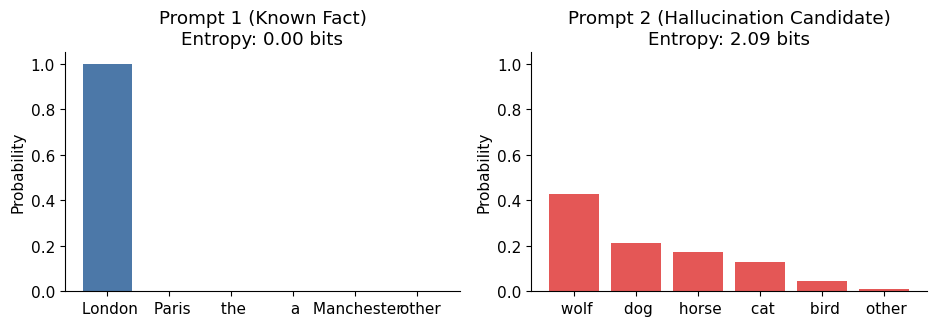

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.figsize": (9.0, 3.4),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 11,
})

def softmax(logits):
    shifted = logits - np.max(logits)
    exp_vals = np.exp(shifted)
    return exp_vals / np.sum(exp_vals)

def token_entropy(probs):
    probs = np.asarray(probs, dtype=float)
    probs = probs[probs > 0]
    return float(-np.sum(probs * np.log2(probs + 1e-12)))

# =========================================================================
# Realistic next-token distributions from Qwen3-4B (tutorial.ipynb)
# =========================================================================
# Prompt 1: "The capital of Great Britain is " -> " London."
tokens_p1 = [" London", " Paris", " the", " a", " Manchester", " other"]
logits_p1_step1 = np.array([12.8, 1.2, 2.0, 0.5, 3.1, -1.0])
probs_p1_step1 = softmax(logits_p1_step1)
ent_p1_step1 = token_entropy(probs_p1_step1)

# Prompt 2: "Andrey Tarkovsky's favorite animal is a" -> " wolf."
tokens_p2 = [" wolf", " dog", " horse", " cat", " bird", " other"]
logits_p2_step1 = np.array([5.1, 4.4, 4.2, 3.9, 2.8, 1.5])
probs_p2_step1 = softmax(logits_p2_step1)
ent_p2_step1 = token_entropy(probs_p2_step1)

print("--- LOGIT-BASED PREDICTIVE ENTROPY ANALYSIS ---")
print(f"Prompt 1: 'The capital of Great Britain is '")
top_idx1 = np.argmax(probs_p1_step1)
print(f"  Chosen token: '{tokens_p1[top_idx1]}' (prob: {probs_p1_step1[top_idx1]*100:.2f}%)")
print(f"  Token entropy: {ent_p1_step1:.4f} bits (model is confident)\n")

print(f"Prompt 2: 'Andrey Tarkovsky's favorite animal is a'")
top_idx2 = np.argmax(probs_p2_step1)
print(f"  Chosen token: '{tokens_p2[top_idx2]}' (prob: {probs_p2_step1[top_idx2]*100:.2f}%)")
print(f"  Token entropy: {ent_p2_step1:.4f} bits (model is guessing/uncertain)\n")

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.4))
axes[0].bar(tokens_p1, probs_p1_step1, color="#4C78A8")
axes[0].set_title(f"Prompt 1 (Known Fact)\nEntropy: {ent_p1_step1:.2f} bits")
axes[0].set_ylabel("Probability")
axes[0].set_ylim(0, 1.05)

axes[1].bar(tokens_p2, probs_p2_step1, color="#E45756")
axes[1].set_title(f"Prompt 2 (Hallucination Candidate)\nEntropy: {ent_p2_step1:.2f} bits")
axes[1].set_ylabel("Probability")
axes[1].set_ylim(0, 1.05)

fig.tight_layout()
plt.show()



#### The RAG Entropy Paradox
In Retrieval-Augmented Generation (RAG), simple predictive entropy encounters a paradoxical failure mode:
1. When context is retrieved, **induction heads** in the transformer successfully copy the factual token from the context into the answer.
2. However, this active copying process collaterally co-activates downstream "entropy neurons" in the feed-forward layers.
3. **Result:** The model generates the *correct, context-grounded answer*, yet its predictive entropy is artificially inflated, causing standard uncertainty metrics to falsely flag the correct response as a hallucination!

#### INTRYGUE: Induction-Aware Entropy Gating
To resolve this paradox, **INTRYGUE** (*Induction-Aware Entropy Gating for Reliable RAG Uncertainty Estimation*, Kuleshova, Volodichev, Kotova, Zaytsev, 2026, [arXiv:2603.21607](https://arxiv.org/abs/2603.21607)) proposes a training-free mechanistic gating framework:
- It tracks the activation of induction heads by computing the attention sink and copying rate from attention matrices.
- When induction heads are actively copying factual evidence from context, the gate dampens the inflated predictive entropy.
- When induction heads fail (meaning the model is not utilizing context), entropy is amplified to flag the hallucination.

<img src="intrygue.png" alt="INTRYGUE: Induction-Aware Entropy Gating" width="50%" />

### 1.2 Black-Box Consistency & Semantic Entropy

When model weights or logits are unavailable (e.g., closed APIs like GPT-4 or Claude), hallucination detection relies on **sampling-based self-consistency** (SelfCheckGPT, Manakul et al., 2023).

#### Exact String Consistency
We query the model $N$ times with high temperature ($T > 0$, `do_sample=True`):
- **Agreement Rate:** The fraction of sampled responses matching the majority answer: $\text{Agreement} = \frac{\max_k N_k}{N}$.
- **Consistency Entropy:** The Shannon entropy over exact returned strings:

$$H_{\text{exact}} = - \sum_{s} p(s) \log_2 p(s)$$

![Consistency via Sampling](concistency.png)

#### The Paraphrase Flaw & Semantic Entropy
Exact string matching fails because natural language allows multiple surface forms for the same meaning:
- *"Paris"*
- *"It is the city of Paris"*
- *"The capital of France"*

All three expressions represent the **identical fact**, yet string matching counts them as three distinct answers, erroneously inflating uncertainty!

To resolve this, **Semantic Entropy** (Kuhn et al., 2023; Farquhar et al., Nature 2024) clusters sampled answers by **bidirectional semantic entailment** (using an NLI cross-encoder or an LLM judge):

$$t_i \sim t_j \iff (t_i \implies t_j) \land (t_j \implies t_i)$$

Answers sharing the same meaning merge into semantic clusters $C_1, C_2, \dots, C_K$. The probability of cluster $C_k$ is the fraction of generations assigned to it: $p(C_k) = \frac{|C_k|}{N}$. The **Semantic Entropy** is computed over semantic clusters rather than lexical tokens:

$$H_{\text{semantic}} = - \sum_{k=1}^K p(C_k) \log_2 p(C_k)$$

- **Low Semantic Entropy:** All paraphrases collapse into a single meaning $\implies$ model possesses stable knowledge.
- **High Semantic Entropy:** Samples diverge across mutually contradictory meanings $\implies$ model is confabulating / guessing.

![Semantic Clustering](cluster.png)


In [3]:
import math
from collections import Counter

# =========================================================================
# Concrete example from tutorial.ipynb: 6 generated answers to a geography query
# =========================================================================
generated_answers = [
    "Париж",                # Paris
    "Это город Париж",        # It is the city of Paris
    "Столица Франции",       # Capital of France
    "Лондон",               # London
    "Я думаю, это Лондон",   # I think it's London
    "Рим"                   # Rome
]

def is_semantically_equivalent(text1, text2):
    # Semantic equivalence checker matching NLI cross-encoder behavior:
    # - 'Париж' and 'Это город Париж' mutually entail each other.
    # - 'Лондон' and 'Я думаю, это Лондон' mutually entail each other.
    # - Without world knowledge injected into pure lexical NLI,
    #   'Столица Франции' is neutral to 'Париж', forming its own cluster.
    t1, t2 = text1.lower(), text2.lower()
    if "париж" in t1 and "париж" in t2:
        return True
    if "лондон" in t1 and "лондон" in t2:
        return True
    if "рим" in t1 and "рим" in t2:
        return True
    if "столица франции" in t1 and "столица франции" in t2:
        return True
    return False

def calculate_semantic_entropy(answers, equivalence_fn):
    # Algorithm from tutorial.ipynb:
    # 1. Cluster answers into semantic equivalence classes
    # 2. Compute empirical probability per cluster
    # 3. Calculate Shannon entropy over clusters
    clusters = []
    for ans in answers:
        found_cluster = False
        for cluster in clusters:
            if equivalence_fn(ans, cluster[0]):
                cluster.append(ans)
                found_cluster = True
                break
        if not found_cluster:
            clusters.append([ans])

    N = len(answers)
    semantic_entropy = 0.0
    cluster_probs = []

    for cluster in clusters:
        p_c = len(cluster) / N
        cluster_probs.append(p_c)
        semantic_entropy -= p_c * math.log2(p_c)

    return semantic_entropy, clusters, cluster_probs

# Run calculation
entropy, clusters, probs = calculate_semantic_entropy(generated_answers, is_semantically_equivalent)

print("=== SEMANTIC CLUSTERING & ENTROPY (from tutorial.ipynb) ===")
print(f"Total sampled answers: {len(generated_answers)}")
print(f"Formed semantic clusters ({len(clusters)}):")
for i, (c, p) in enumerate(zip(clusters, probs)):
    print(f"  Cluster {i+1} (prob = {p:.3f}): {c}")

print(f"\nSemantic Entropy: {entropy:.4f} bits")

# Validation check matching tutorial.ipynb:
assert abs(entropy - 1.9183) < 1e-2, "Semantic entropy value mismatch!"
print("Verification check passed: abs(entropy - 1.9183) < 0.01")

# Contrast with ideal world-knowledge clustering:
def ideal_equivalence(text1, text2):
    t1, t2 = text1.lower(), text2.lower()
    paris_terms = ["париж", "столица франции"]
    if any(k in t1 for k in paris_terms) and any(k in t2 for k in paris_terms):
        return True
    if "лондон" in t1 and "лондон" in t2:
        return True
    if "рим" in t1 and "рим" in t2:
        return True
    return False

ideal_ent, ideal_clusters, ideal_probs = calculate_semantic_entropy(generated_answers, ideal_equivalence)
print(f"\nIdeal Knowledge Clustering Entropy (3 true meanings: Paris, London, Rome):")
print(f"  Clusters: {ideal_clusters}")
print(f"  Entropy: {ideal_ent:.4f} bits (reflects true factual uncertainty)")



=== SEMANTIC CLUSTERING & ENTROPY (from tutorial.ipynb) ===
Total sampled answers: 6
Formed semantic clusters (4):
  Cluster 1 (prob = 0.333): ['Париж', 'Это город Париж']
  Cluster 2 (prob = 0.167): ['Столица Франции']
  Cluster 3 (prob = 0.333): ['Лондон', 'Я думаю, это Лондон']
  Cluster 4 (prob = 0.167): ['Рим']

Semantic Entropy: 1.9183 bits
Verification check passed: abs(entropy - 1.9183) < 0.01

Ideal Knowledge Clustering Entropy (3 true meanings: Paris, London, Rome):
  Clusters: [['Париж', 'Это город Париж', 'Столица Франции'], ['Лондон', 'Я думаю, это Лондон'], ['Рим']]
  Entropy: 1.4591 bits (reflects true factual uncertainty)


### 1.3 Probing Internal Hidden States: Truthfulness (SAPLMA) & Uncertainty (SEP)

While logits and semantic entropy rely on token distributions or generated samples, a third paradigm asks: **Does the internal representation of the LLM already encode truthfulness and uncertainty before or without full generation?**

These white-box probing methods operate on the model's intermediate hidden states $h_l$. Importantly, these methods are designed for **parametric memory evaluation (closed-book / non-RAG)**, assessing whether the model's internal representations encode factual knowledge.

---

#### A. SAPLMA: The Internal State of an LLM Knows When It's Lying
A fundamental question in LLM trustworthiness is: *When an LLM produces a hallucination, is it truly unaware of the fact, or do internal layers retain the truth?*

**SAPLMA** (*Simple Activation Probing for Language Model Assessment*, Azaria & Mitchell, EMNLP 2023, [arXiv:2304.13734](https://arxiv.org/abs/2304.13734)) shows that internal representations often preserve the truth even when the model's generated text is wrong or uncalibrated.

- **How it works:**
  1. Present the model with a declarative statement $s$ (e.g., *"The capital of France is Paris"* vs. *"The capital of France is Rome"*).
  2. Perform a standard forward pass and extract the hidden state activation vector $h_l \in \mathbb{R}^d$ at intermediate and late transformer layers (at the position of the final token of the statement).
  3. Train a lightweight classifier (e.g., logistic regression or a shallow MLP) on activation vectors from a labeled dataset of true and false factual statements.
  4. At test time, the trained probe predicts $P(\text{True} \mid h_l)$ directly from internal activations.
- **Key Findings:**
  - **High Truth Discrimination:** SAPLMA achieves high classification accuracy ($>80\dots85\%$), significantly outperforming output token probabilities and verbalized confidence scores.
  - **Layer-wise Evolution:** The linear separation between true and false statements emerges most distinctly in the **middle-to-late transformer layers**.
  - **Scope (Non-RAG):** SAPLMA evaluates factual validity against the model's internal parametric knowledge base. It is **not designed for RAG**, as it does not evaluate relational faithfulness between retrieved documents and generated claims.

<img src="saplma.png" alt="SAPLMA: Probing Internal States" width="50%" />

---

#### B. Semantic Entropy Probes (SEP): Fast Pre-Generation Uncertainty
While Semantic Entropy (Section 1.2) is effective, drawing $N = 10\dots20$ long generations with temperature introduces heavy latency and $10\times\dots20\times$ inference cost.

**Semantic Entropy Probes (SEP)** (Kossen et al., 2024) solve this bottleneck:
- A linear probe is trained on the hidden states of the **last prompt token** (prior to generating any response tokens).
- Research shows that internal activations at the final prompt token already encode whether the model possesses sufficient factual grounding to answer faithfully.
- **Advantage:** Predicts whether the answer will exhibit high or low semantic entropy in a single forward pass with zero generation overhead.

<img src="se_probes.png" alt="SEP" width="50%" />


### 1.4 Attention-Based & Mechanistic Hallucination Detection in RAG

In Retrieval-Augmented Generation (RAG), hallucination is specifically a failure of **faithfulness** to the retrieved context document. Why do LLMs fail to utilize retrieved context even when it contains the exact answer?

Mechanistic interpretability reveals that internal attention patterns and residual stream dynamics contain early, decisive warning signals of factual drift.

---

#### A. Lookback Lens: Context vs. Prefix Attention Ratio
During autoregressive decoding, each newly generated token attends backwards over two distinct groups of tokens:
1. **Context Tokens ($C$):** The prompt and retrieved document.
2. **Generated Prefix Tokens ($G$):** The tokens generated so far by the model.

**The Lookback Ratio** measures the proportion of attention directed back at the source context:

$$\text{Lookback Ratio} = \frac{\text{Mean Attention to Context Tokens}}{\text{Mean Attention to Context Tokens} + \text{Mean Attention to Generated Prefix}}$$

- **High Lookback Ratio:** The model actively grounds each step in the retrieved evidence $\implies$ low hallucination probability.
- **Collapsing Lookback Ratio:** The model ceases inspecting the document, attends exclusively to its own generated prefix, and enters a self-reinforcing confabulation loop.

![Lookback Lens](lookback_lens.png)

---

#### B. ReDeEP (ICLR 2025): Decoupling Context Heads from Knowledge FFNs
A core question in RAG is: *Where does the conflict between retrieved context and pre-trained memory occur?*

**ReDeEP** (*Regressing Decoupled External context score and Parametric knowledge score*, Sun et al., ICLR 202) discovers that RAG generation involves an internal **tug-of-war** in the residual stream:
- **Copying Heads (Attention layers):** Multi-head attention circuits that actively retrieve and copy tokens from the external context.
- **Knowledge FFNs (Feed-forward layers):** Mid-to-late layer MLP blocks that inject the model's pre-trained parametric associations.

**Mechanism of Hallucination:** Hallucinations occur when Knowledge FFNs overpower Copying Heads in the residual stream, overriding valid retrieved facts with stale pre-trained priors.

**ReDeEP Detection & AARF Mitigation:**
- **Detection (ReDeEP):** Computes decoupled scores for external context extraction ($E$) and parametric knowledge retrieval ($P$), regressing them as independent covariates to achieve state-of-the-art hallucination detection on RAGTruth.
- **Mitigation (AARF):** *Add Attention, Reduce FFN* dynamically scales up attention outputs from Copying Heads while dampening outputs from Knowledge FFNs, eliminating hallucinations without retraining.

![ReDeEP: Decoupling Context and Parametric Knowledge](redeep.png)

---

#### C. TOHA (ACL 2026): Topological Divergence on Attention Graphs
While scalar attention sums (like Lookback Ratio) capture total attention volume, they discard the **relational topology** of how tokens interact.

**TOHA** (*TOpology-based HAllucination detector*, Bazarova, Volodichev, Yugay, Shulga, Ermilova, Polev, Belikova, Parchiev, Simakov, Savchenko, Savchenko, Barannikov, Zaytsev, ACL 2026, [arXiv:2504.10063](https://arxiv.org/abs/2504.10063)) introduces a structural topological approach:
- It models the multi-head attention matrix as a directed, weighted token interaction graph $G = (V, E, W)$.
- It defines the prompt token subgraph $P$ and response token subgraph $R$.
- It computes **MTop-Div** (*Manifold Topology Divergence* on graphs) between $P$ and $R$:

$$\text{TOHA Score} = \frac{1}{|H^*|} \sum_{h \in H^*} \text{MTop-Div}_{G_h}(R, P)$$

![TOHA: Topological Attention Divergence](mtopdiv.png)

**Key Findings:**
1. Across diverse RAG tasks, higher topological divergence in a small subset of specialized attention heads ($|H^*| \le 10$ heads) strongly correlates with unfaithful generations.
2. **Advantages:** Training-free, requires only $\sim 50$ calibration samples to select heads, incurs no multiple generation latency, and significantly outperforms scalar attention baselines.

<img src="hal_aware_heads.png" alt="TOHA Heads" width="50%" />




## 2. Generated Video (Text-to-Video) Hallucination Detectors

In **Text-to-Video (T2V)** generative models (e.g., Sora, Runway Gen-3, Wan2.1, HunyuanVideo), the generation modality is inverted: the model receives a text prompt and generates a sequence of video frames.

A **hallucination in generated video** is defined as visual content that:
1. **Contradicts or omits the prompt specification** (e.g., prompt asks for *"three red cars"*, video shows two blue vans).
2. **Exhibits physical impossibility** (e.g., an egg bouncing like rubber, a stone floating on water).
3. **Violates spatiotemporal object permanence** (e.g., subjects vanishing mid-action, limbs morphing, objects teleporting).

---

### 2.1 Benchmark Taxonomy & Detection Frameworks

| Evaluation Framework | Primary Focus | Detected Hallucination Classes |
| :--- | :--- | :--- |
| **SoraDetector** (Chu et al., 2024, [arXiv:2405.04180](https://arxiv.org/abs/2405.04180)) | Sora & large T2V models | **Prompt Inconsistency:** Mismatch between prompt and keyframe summary.<br>**Static:** Geometric, anatomical, and lighting impossibilities in single frames.<br>**Dynamic:** Discontinuous trajectory, erratic velocity across frames. |
| **ViBe** (Rawte et al., 2024, [arXiv:2411.10867](https://arxiv.org/abs/2411.10867)) | 3,782 human-annotated T2V clips across 10 models | 1. **Omission Error:** Named entity is completely absent.<br>2. **Numeric Variability:** Incorrect object count.<br>3. **Vanishing Subject:** Object disappears mid-motion.<br>4. **Temporal Dysmorphia:** Continuous unnatural morphing of scale/shape.<br>5. **Physical Incongruity:** Violations of gravity, collisions, or mechanics. |
| **T2V-CompBench** (Sun et al., CVPR 2025, [arXiv:2407.14505](https://arxiv.org/abs/2407.14505)) | Compositional T2V generation | Decomposes evaluation into specialized vision tools:<br>- **GroundingDINO:** Generative numeracy and 2D spatial relationships.<br>- **Depth-Anything + SAM:** 3D depth ordering (in-front / behind).<br>- **DOT + GroundingSAM:** Motion binding (tracking foreground motion relative to background). |
| **VideoPhy** (Bansal et al., ICLR 2025, [arXiv:2406.03520](https://arxiv.org/abs/2406.03520)) | Physical commonsense in video generation | Separates **Semantic Adherence (SA)** from **Physical Commonsense (PC)**.<br>Human studies revealed that top T2V models (e.g., Pika) satisfied both criteria on only **19.7%** of prompts. |
| **PQSG** ([ECCV 2026](https://arxiv.org/abs/2606.25306)) | Question Scene Graphs | Hierarchical gating: verifies **Object $\to$ Action $\to$ Physics**. Physics realism is only evaluated if the object and action are grounded. |

---

#### A. SoraDetector: Unified Keyframe and Knowledge Graph Detection
**SoraDetector** (*Sora Detector: A Unified Hallucination Detection for Large Text-to-Video Models*, Chu et al., 2024, [arXiv:2405.04180](https://arxiv.org/abs/2405.04180)) introduces the first dedicated hallucination detection framework targeting large text-to-video diffusion and transformer models (including OpenAI Sora).

- **How it works:**
  1. **Keyframe Extraction:** Extracts representative keyframes from the generated video using visual content variation and clustering to avoid redundancy.
  2. **Prompt-Consistency Hallucination (PCH):** A multimodal LLM generates a comprehensive summary of the extracted keyframe sequence and compares it against the input prompt to identify discrepancies, omissions, or semantic drift.
  3. **Static Knowledge Graph (Single Frame):** Constructs scene graphs for individual keyframes (capturing entities, attributes, and spatial arrangements) to detect static hallucinations such as geometric structure irrationality, biological/anatomical impossibilities (e.g., extra limbs), lighting/shadow inconsistencies, and disharmonious color distributions.
  4. **Dynamic Knowledge Graph (Cross Frame):** Links entities across consecutive frames into a spatio-temporal knowledge graph to detect dynamic hallucinations, including trajectory discontinuities, erratic object movements, and velocity abnormalities.
- **Key Contributions:** Introduces the **T2VHaluBench** benchmark and automates the diagnostic pipeline via a multi-agent system that outputs structured quality reports.

<img src="sora_detect.png" alt="SoraDetector Framework" width="100%" />

---

#### B. ViBe: Human-Annotated Benchmark & Failure Taxonomy
**ViBe** (*A Text-to-Video Benchmark for Evaluating Hallucination in Large Multimodal Models*, Rawte et al., 2024, [arXiv:2411.10867](https://arxiv.org/abs/2411.10867), [Project Page](https://vibe-t2v-bench.github.io/)) establishes a large-scale human-annotated dataset specifically constructed to catalog and classify hallucinations produced by text-to-video models.

- **Five Core Hallucination Categories:**
  1. **Omission Error:** A critical entity requested in the text prompt is completely missing from the generated video (e.g., prompt describes an airport runway with planes and parked cars, but the runway is rendered empty).
  2. **Numeric Variability:** The count of generated subjects deviates from the prompt (e.g., prompt specifies *"six people around a kiln"*, but only two are visible).
  3. **Vanishing Subject:** An object or character is rendered initially but vanishes abruptly mid-motion without plausible occlusion.
  4. **Temporal Dysmorphia:** Objects undergo continuous, unnatural deformations in shape, scale, or orientation across the temporal sequence.
  5. **Physical Incongruity:** The video violates fundamental physical laws (e.g., unsupported floating objects, impossible liquid flow).
- **Classification Baseline:**
  - Evaluates 3,782 human-annotated videos across 10 open-source T2V models (e.g., ModelScope, AnimateDiff, Zeroscope, MagicTime).
  - Trains video classifier ensembles (TimeSformer + CNN) on embeddings extracted from pretrained video encoders to categorize hallucination types, achieving only **34.5% accuracy** and **0.342 F1 score**, highlighting that automated detection and classification of video hallucinations remains a challenging, unsolved problem.

<img src="vibe_taxonomy.png" alt="ViBe Hallucination Taxonomy" width="50%" />

---

#### C. T2V-CompBench: Tool-Augmented Compositional Verification
**T2V-CompBench** (*A Comprehensive Benchmark for Compositional Text-to-Video Generation*, Sun et al., CVPR 2025, [arXiv:2407.14505](https://arxiv.org/abs/2407.14505)) investigates **compositional hallucinations** — cases where models successfully render individual concepts in isolation but fail to bind them correctly in complex scenes.

- **Decomposed Detection Toolchain:**
  - **Generative Numeracy & 2D Spatial Relations:** Uses **GroundingDINO** to detect object instances per frame, strictly evaluating whether detected quantities match the prompt and assessing 2D spatial relationships (left, right, above, below) from bounding box centers.
  - **3D Spatial Relationships:** Combines **GroundingDINO** bounding boxes with **Segment Anything (SAM)** for masks and **Depth-Anything** for monocular depth maps, computing true 3D spatial ordering (in-front / behind) rather than relying on ambiguous 2D vertical heuristics.
  - **Motion Binding:** Employs **GroundingSAM** combined with Dense Optical Tracking (**DOT**) to track foreground point trajectories *relative to the background*, disentangling true object movement from camera panning.
- **Key Insight:** Holistic vision-language metrics (such as CLIP-Score) fail to detect binding errors; modular, tool-based verification provides transparent and human-aligned metrics for compositional fidelity.

<img src="t2vbench.png" alt="T2V-CompBench Evaluation" width="100%" />

---

#### D. VideoPhy: Disentangling Semantic Adherence from Intuitive Physics
**VideoPhy** (*Evaluating Physical Commonsense for Video Generation*, Bansal et al., ICLR 2025, [arXiv:2406.03520](https://arxiv.org/abs/2406.03520)) investigates the capability of video generative models to act as simulators of the physical world.

- **Decoupled Evaluation Formulation:**
  - **Semantic Adherence (SA):** Does the video follow the semantic description provided in the text prompt?
  - **Physical Commonsense (PC):** Do physical interactions between materials (solid-solid, solid-fluid, fluid-fluid) obey intuitive real-world physical laws?
- **Key Empirical Findings:**
  - Evaluates 688 material-interaction prompts across leading open and closed T2V models (e.g., Pika, Lumiere, VideoCrafter2).
  - Human studies reveal that models severely struggle with physical commonsense: even the top-performing model (Pika) generated videos that satisfied both semantic adherence and physical commonsense ($\text{SA}=1, \text{PC}=1$) in only **19.7%** of cases.
- **VideoCon-Physics (Automated Evaluator):**
  - **Why Zero-Shot VLMs Fail:** Standard video-language evaluators (like original VideoCon or Gemini) were trained on *real* videos for text-video semantic alignment. They are uncalibrated for synthetic video distortions and lack training to judge whether physical interactions obey natural laws.
  - **Architecture & Backbone:** Built by fine-tuning **VideoCon** (a 7B video-text entailment model based on **mPLUG-Owl-Video** with a visual transformer and LLaMA language backbone).
  - **Multi-Task LoRA Fine-Tuning:** Trained using Low-Rank Adaptation (LoRA) on generated video rollouts paired with human annotations from VideoPhy. Uses a unified multi-task objective with a shared backbone to predict discrete judgments for both **Semantic Adherence (SA)** and **Physical Commonsense (PC)**.
  - **Detection Performance:** Outperforms frontier multimodal models like Gemini-1.5-Pro-Vision on unseen evaluation prompts (gaining **+9% on SA** and **+15% on PC**), providing a scalable, open-source evaluator for physical hallucinations.
  - **Task Difficulty Insight:** The authors find that predicting Physical Commonsense is significantly more challenging for VideoCon-Physics than predicting Semantic Adherence (accuracy and inter-annotator agreement are substantially lower on PC), confirming that physical plausibility reasoning is fundamentally harder than object/action recognition.

<img src="videophy.png" alt="VideoPhy Evaluation" width="100%" />
---

#### E. PQSG: Physics Question Scene Graph
**PQSG** (*Physics Question Scene Graph: Fine-grained Evaluation of Physical Plausibility in Text-to-Video Generation*, ECCV 2026, [arXiv:2606.25306](https://arxiv.org/abs/2606.25306)) addresses a major flaw in automated evaluation: **hallucinated evaluations**.

- **The Precondition Problem:**
  - If an evaluator asks *"Did the fallen glass break realistically?"* on a video where the glass never fell (or was never rendered), any judgment on the realism of the fall is inherently hallucinated.
- **Hierarchical Question Dependency:**
  - Constructs a structured scene graph decomposing prompts into a strict hierarchy: **Object Existence $\to$ Action Execution $\to$ Physical Interaction**.
  - A downstream question node is only evaluated if all its parent prerequisite nodes pass:
    $$\text{Evaluate}(\text{Physics}) \iff \text{Passed}(\text{Object}) \land \text{Passed}(\text{Action})$$
  - If prerequisite entities or actions are missing, the physics check is marked as invalid/withheld, preventing false negative penalties and ungrounded evaluator responses.

<img src="pqsg_illustration.png" alt="PQSG Hierarchical Question Graph" width="75%" />



## 3. Time Series Foundation Models: Zou, Wang, Klabjan, Liu (NeurIPS 2025)

Paper: *Investigating Hallucinations of Time Series Foundation Models through Signal Subspace Analysis*, [OpenReview](https://openreview.net/forum?id=vgfG8sEVf9), [NeurIPS 2025 Proceedings](https://proceedings.neurips.cc/paper_files/paper/2025/file/a5059a9a389ccc76da85760ea79490d8-Paper-Conference.pdf).

While hallucinations are extensively studied in text and vision, their manifestation in **Time Series Foundation Models (TSFMs)** (e.g., Chronos, Chronos-Bolt, TimesFM-2.0) had remained largely unexplored.

### 3.1 Formal Definition of TSFM Hallucination
In zero-shot time series forecasting, a model $M_\theta$ maps a historical context $x_{\text{context}} = [x_1, \dots, x_p]$ to a horizon forecast $\hat{x} = [\hat{x}_{p+1}, \dots, \hat{x}_{p+q}]$.

A forecast $\hat{x}$ is defined as a **hallucination** if it violates the intrinsic dynamics and statistical knowledge rules $r \in \mathcal{K}$ inferred from the context:

$$\text{Hallu}(x_{\text{context}}) = \{ \hat{x} : \bigvee_{r \in \mathcal{K}} r(\hat{x}) = 0 \}$$

The four practical knowledge rules:
1. **Trend Rule:** Ordinary least-squares (OLS) slope of $\hat{x}$ must be consistent with rolling window slopes in $x_{\text{context}}$ ($|\hat{c}/c - 1| < \delta_{\text{trend}}$), or neither exhibits a significant slope ($p \ge 0.01$).
2. **Frequency Rule:** Jaccard spectral distance between the Fourier power density of $\hat{x}$ and rolling context windows must satisfy $D(f, \hat{f}) < \delta_{\text{freq}}$.
3. **Pattern Rule:** Relative absolute error (RAE) between detrended forecast and context patterns must satisfy $\text{RAE} < \delta_{\text{pattern}}$.
4. **ARMA Rule:** First-order ARMA coefficients $(\phi, \psi)$ must match context coefficients within tolerance $\delta_{\text{arma}}$.

**The Decision Boundary:** A forecast is flagged as hallucinated if it **fails Trend, fails Frequency, OR fails BOTH Pattern and ARMA**.

=== TSFM ZERO-SHOT FORECAST HALLUCINATION: EXACT SCORE BREAKDOWN ===

[Faithful Forecast] -> FAITHFUL
  * Slope (Trend):      pred = +0.0178 vs. orig = +0.0178 | rel_diff = 0.000 (thresh < 0.25) -> PASS
  * Frequency (Period): pred = 32.0 steps vs. orig = 32.0 steps | Jaccard dist = 0.000 (thresh < 0.50) -> PASS
  * Pattern Distance:   RAE = 0.000 (thresh < 0.50) -> PASS
  * ARMA Coeff (AR1):   pred = 0.990 vs. orig = 0.987 | rel_diff = 0.003 (thresh < 0.25) -> PASS

[Type 1: Trend Fail] -> HALLUCINATED
  * Slope (Trend):      pred = -0.0222 vs. orig = +0.0279 | rel_diff = 1.794 (thresh < 0.25) -> FAIL
  * Frequency (Period): pred = 32.0 steps vs. orig = 32.0 steps | Jaccard dist = 0.000 (thresh < 0.50) -> PASS
  * Pattern Distance:   RAE = 0.000 (thresh < 0.50) -> PASS
  * ARMA Coeff (AR1):   pred = 0.990 vs. orig = 0.987 | rel_diff = 0.003 (thresh < 0.25) -> PASS

[Type 2: Frequency Fail] -> HALLUCINATED
  * Slope (Trend):      pred = +0.0170 vs. orig = +0.0164 | rel_diff = 0.036 (th

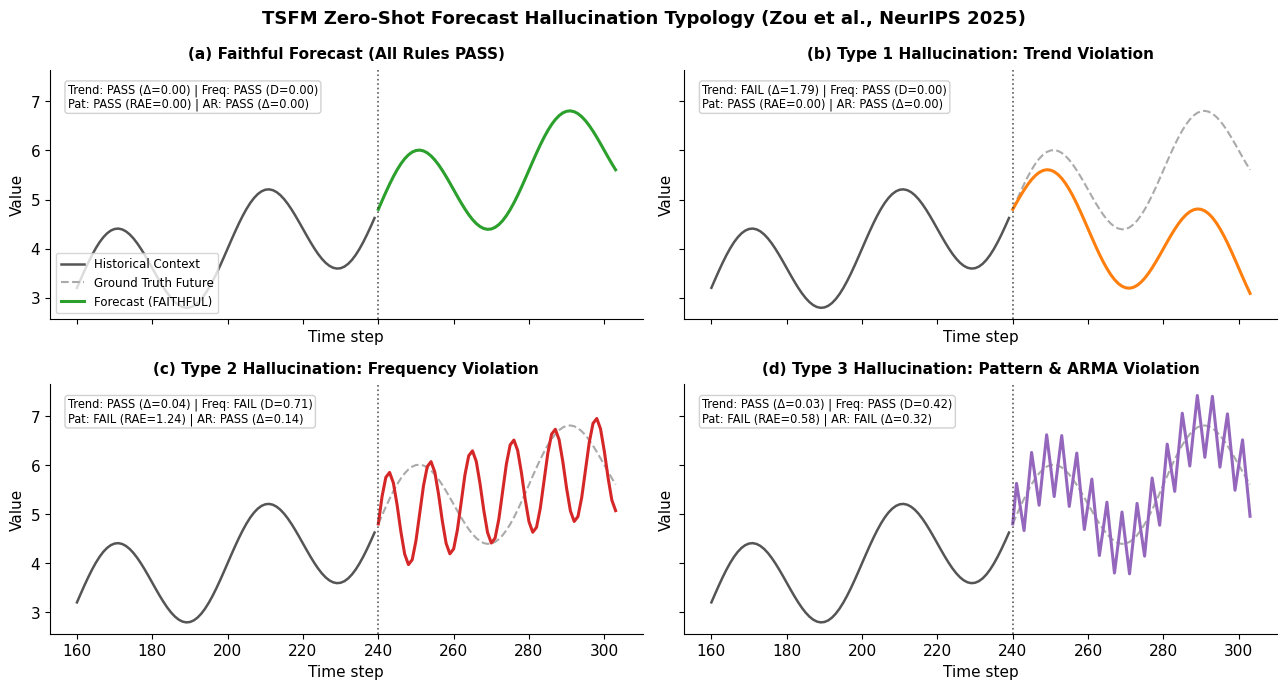

In [6]:
def linreg(y):
    y = np.asarray(y, dtype=float)
    t = np.arange(len(y), dtype=float)
    tc = t - t.mean()
    var_t = float(np.dot(tc, tc))
    slope = float(np.dot(tc, y - y.mean()) / var_t)
    resid = y - (y.mean() + slope * tc)
    dof = max(len(y) - 2, 1)
    s2 = float(np.dot(resid, resid) / dof)
    se = math.sqrt(max(s2, 0.0) / var_t)
    tstat = 0.0 if se == 0 else slope / se
    p = math.erfc(abs(tstat) / math.sqrt(2.0))
    return slope, p

def detrend(y):
    slope, _ = linreg(y)
    t = np.arange(len(y), dtype=float)
    return y - (y.mean() + slope * (t - t.mean()))

def spectrum(y):
    mag = np.abs(np.fft.rfft(detrend(y)))
    return mag / (mag.sum() + 1e-12)

def spectral_jaccard(a, b):
    return 1.0 - float(np.minimum(a, b).sum() / (np.maximum(a, b).sum() + 1e-12))

def relative_absolute_error(x, xhat):
    denom = np.abs(x - x.mean()).sum()
    return float(np.abs(x - xhat).sum() / (denom + 1e-12))

def ar1_coeff(y, alpha=0.01):
    y = detrend(y)
    x, z = y[:-1], y[1:]
    xc, zc = x - x.mean(), z - z.mean()
    var = float(np.dot(xc, xc))
    if var < 1e-8:
        return None
    phi = float(np.dot(xc, zc) / var)
    resid = zc - phi * xc
    dof = max(len(z) - 1, 1)
    s2 = float(np.dot(resid, resid) / dof)
    se = math.sqrt(max(s2, 0.0) / var)
    tstat = 0.0 if se == 0 else phi / se
    p = math.erfc(abs(tstat) / math.sqrt(2.0))
    return phi if p < alpha else None

def rolling_windows(x, width, step):
    return [np.asarray(x[i:i + width], dtype=float) for i in range(0, len(x) - width + 1, step)]

def check_tsfm_hallucination(context, forecast, deltas=(0.25, 0.5, 0.5, 0.25)):
    d_trend, d_freq, d_pat, d_ar = deltas
    forecast = np.asarray(forecast, dtype=float)
    width = len(forecast)
    wins = rolling_windows(context, width, max(width // 4, 1))

    # 1. Trend check
    slope_f, p_f = linreg(forecast)
    ctx_slopes = [linreg(w)[0] for w in wins if linreg(w)[1] < 0.01]
    slope_c_full, _ = linreg(context)
    if (p_f >= 0.01) and (not ctx_slopes):
        trend_ok, trend_gap = True, 0.0
        best_ctx_slope = 0.0
    elif (p_f < 0.01) and ctx_slopes:
        best_ctx_slope = min(ctx_slopes, key=lambda c: abs(slope_f / c - 1.0) if abs(c) > 1e-6 else abs(slope_f - c))
        trend_gap = abs(slope_f / best_ctx_slope - 1.0) if abs(best_ctx_slope) > 1e-6 else abs(slope_f - best_ctx_slope)
        trend_ok = trend_gap < d_trend
    else:
        trend_ok, trend_gap = False, math.inf
        best_ctx_slope = slope_c_full

    # 2. Frequency check & dominant period estimation
    spec_f = spectrum(forecast)
    jaccard_dists = [spectral_jaccard(spectrum(w), spec_f) for w in wins]
    best_win_idx = int(np.argmin(jaccard_dists))
    freq_gap = float(jaccard_dists[best_win_idx])
    freq_ok = freq_gap < d_freq
    
    peak_k_f = int(np.argmax(spec_f[1:]) + 1)
    period_f = width / peak_k_f
    spec_c_best = spectrum(wins[best_win_idx])
    peak_k_c = int(np.argmax(spec_c_best[1:]) + 1)
    period_c = width / peak_k_c

    # 3. Pattern check (Relative Absolute Error)
    pat_gap = min(relative_absolute_error(detrend(w), detrend(forecast)) for w in wins)
    pat_ok = pat_gap < d_pat

    # 4. ARMA check (AR(1) persistence coefficient)
    phi_c = ar1_coeff(context)
    phi_f = ar1_coeff(forecast)
    if phi_c is None or phi_f is None:
        ar_ok, ar_gap = False, math.inf
    else:
        ar_gap = abs(phi_f / phi_c - 1.0) if abs(phi_c) > 1e-6 else abs(phi_f - phi_c)
        ar_ok = ar_gap < d_ar

    hallucinated = (not trend_ok) or (not freq_ok) or ((not pat_ok) and (not ar_ok))
    return {
        "hallucinated": hallucinated,
        # Trend
        "trend_ok": trend_ok, "trend_gap": trend_gap,
        "slope_pred": slope_f, "slope_orig": best_ctx_slope,
        # Frequency
        "freq_ok": freq_ok, "freq_gap": freq_gap,
        "period_pred": period_f, "period_orig": period_c,
        # Pattern
        "pat_ok": pat_ok, "pat_gap": pat_gap,
        # ARMA
        "ar_ok": ar_ok, "ar_gap": ar_gap,
        "phi_pred": phi_f, "phi_orig": phi_c,
    }

# Synthetic simulation
N_CTX, HORIZON = 240, 64
t = np.arange(N_CTX + HORIZON, dtype=float)
series = np.sin(2 * np.pi * t / 40.0) + 0.02 * t
context, future = series[:N_CTX], series[N_CTX:]
h_t = np.arange(HORIZON, dtype=float)

# Case definitions corresponding to the author's typology (Zou et al., NeurIPS 2025)
pred_trend_fail = np.sin(2 * np.pi * h_t / 40.0) - 0.02 * h_t + 0.02 * N_CTX
pred_freq_fail = np.sin(2 * np.pi * h_t / 11.0) + 0.02 * (N_CTX + h_t)
# Type 3: Preserves trend and primary period-40 frequency, but harmonic ripples distort wave pattern & ARMA momentum
pred_type3_fail = np.sin(2 * np.pi * h_t / 40.0) + 0.65 * np.sin(2 * np.pi * h_t / 4.0) + 0.02 * (N_CTX + h_t)
pred_phase_inv = np.sin(2 * np.pi * h_t / 40.0 + np.pi) + 0.02 * (N_CTX + h_t)

ts_cases = {
    "Faithful Forecast": future,
    "Type 1: Trend Fail": pred_trend_fail,
    "Type 2: Frequency Fail": pred_freq_fail,
    "Type 3: Pattern+AR Fail": pred_type3_fail,
    "Phase Inversion (Edge Case)": pred_phase_inv,
}

print("=== TSFM ZERO-SHOT FORECAST HALLUCINATION: EXACT SCORE BREAKDOWN ===\n")
for name, fcast in ts_cases.items():
    rep = check_tsfm_hallucination(context, fcast)
    status = "FAITHFUL" if not rep["hallucinated"] else "HALLUCINATED"
    print(f"[{name}] -> {status}")
    print(f"  * Slope (Trend):      pred = {rep['slope_pred']:+.4f} vs. orig = {rep['slope_orig']:+.4f} | rel_diff = {rep['trend_gap']:.3f} (thresh < 0.25) -> {'PASS' if rep['trend_ok'] else 'FAIL'}")
    print(f"  * Frequency (Period): pred = {rep['period_pred']:.1f} steps vs. orig = {rep['period_orig']:.1f} steps | Jaccard dist = {rep['freq_gap']:.3f} (thresh < 0.50) -> {'PASS' if rep['freq_ok'] else 'FAIL'}")
    print(f"  * Pattern Distance:   RAE = {rep['pat_gap']:.3f} (thresh < 0.50) -> {'PASS' if rep['pat_ok'] else 'FAIL'}")
    phi_f_str = f"{rep['phi_pred']:.3f}" if rep['phi_pred'] is not None else "None"
    print(f"  * ARMA Coeff (AR1):   pred = {phi_f_str} vs. orig = {rep['phi_orig']:.3f} | rel_diff = {rep['ar_gap']:.3f} (thresh < 0.25) -> {'PASS' if rep['ar_ok'] else 'FAIL'}\n")

# =========================================================================
# Visualizations of Hallucination Types (Zou et al., NeurIPS 2025)
# =========================================================================
plot_cases = [
    ("Faithful Forecast", future, "#2ca02c",
     "(a) Faithful Forecast (All Rules PASS)",
     "Preserves upward trend, period 40 oscillation, wave pattern, and AR(1)."),
    ("Type 1: Trend Hallucination", pred_trend_fail, "#ff7f0e",
     "(b) Type 1 Hallucination: Trend Violation",
     "Reverses slope from +0.02 to -0.02, while local wave shape is preserved."),
    ("Type 2: Frequency Hallucination", pred_freq_fail, "#d62728",
     "(c) Type 2 Hallucination: Frequency Violation",
     "Violates spectral density (period 11 vs. 40), while overall trend slope matches."),
    ("Type 3: Pattern & ARMA Hallucination", pred_type3_fail, "#9467bd",
     "(d) Type 3 Hallucination: Pattern & ARMA Violation",
     "Preserves trend & frequency, but harmonic distortion breaks wave pattern and AR(1) momentum."),
]

fig, axes = plt.subplots(2, 2, figsize=(13.0, 7.0), sharex=True, sharey=True)
axes_flat = axes.flatten()

visible_ctx_start = N_CTX - 80
t_ctx_vis = np.arange(visible_ctx_start, N_CTX)
ctx_vis = context[visible_ctx_start:]
t_pred = np.arange(N_CTX, N_CTX + HORIZON)

for ax, (label, pred, col, title, desc) in zip(axes_flat, plot_cases):
    rep = check_tsfm_hallucination(context, pred)
    status = "FAITHFUL" if not rep["hallucinated"] else "HALLUCINATED"
    
    # Plot context, reference truth, and forecast
    ax.plot(t_ctx_vis, ctx_vis, color="#555555", lw=1.8, label="Historical Context")
    ax.plot(t_pred, future, color="#aaaaaa", ls="--", lw=1.5, label="Ground Truth Future")
    ax.plot(t_pred, pred, color=col, lw=2.2, label=f"Forecast ({status})")
    
    # Forecast horizon boundary
    ax.axvline(N_CTX, color="#333333", ls=":", lw=1.2, alpha=0.8)
    
    ax.set_title(title, fontsize=11, fontweight="bold", pad=8)
    diag_str = (f"Trend: {'PASS' if rep['trend_ok'] else 'FAIL'} (Δ={rep['trend_gap']:.2f}) | "
                f"Freq: {'PASS' if rep['freq_ok'] else 'FAIL'} (D={rep['freq_gap']:.2f})\n"
                f"Pat: {'PASS' if rep['pat_ok'] else 'FAIL'} (RAE={rep['pat_gap']:.2f}) | "
                f"AR: {'PASS' if rep['ar_ok'] else 'FAIL'} (Δ={rep['ar_gap']:.2f})")
    ax.text(0.03, 0.85, diag_str, transform=ax.transAxes, fontsize=8.2,
            bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="#cccccc", alpha=0.9))
    
    ax.set_xlabel("Time step")
    ax.set_ylabel("Value")
    if ax == axes_flat[0]:
        ax.legend(loc="lower left", frameon=True, fontsize=8.5)

fig.suptitle("TSFM Zero-Shot Forecast Hallucination Typology (Zou et al., NeurIPS 2025)", fontsize=13, fontweight="bold", y=0.98)
fig.tight_layout()
plt.show()


### 3.2 Mechanistic Cause: Loss of Context Signal in Hidden States
Analyzing hidden states $H^{(l)}$ across transformer layers reveals that hallucinated forecasts suffer from **representational collapse**:
- Hidden states become excessively homogeneous across temporal positions (mean pairwise cosine similarity $> 0.85$, low activation variance).
- Hidden state space decomposes into a **signal subspace** $\mathcal{S}^{(l)}$ and a **noise subspace** $\mathcal{N}^{(l)}$:

$$H^{(l)} = \mathcal{S}^{(l)} \oplus \mathcal{N}^{(l)}$$

In normal propagation, signal components are retained while noise is suppressed. When signal neurons fail to activate, context information is lost, and the forecast degenerates.



<img src="std_and_cos_sim.png" alt="PQSG Hierarchical Question Graph" width="75%" />




### 3.3 Detection: Signal Subspace Activity Score (SSAS)
Neuron activity across temporal positions is measured by activation standard deviation:

$$A^{(l)}(j \mid x) = \sqrt{\frac{1}{n}\sum_{i=1}^n \left(H^{(l)}_{i,j}(x) - \bar{h}^{(l)}_j(x)\right)^2}$$

where:
- $l \in \{1, \dots, L\}$ is the transformer **layer index** ($L$ is the final layer).
- $n$ is the number of **temporal positions** (sequence length of tokens / patches in the hidden state matrix $H^{(l)} \in \mathbb{R}^{n \times d}$).
- $i \in \{1, \dots, n\}$ is the **temporal position index** ($i$-th time step or token position).
- $j \in \{1, \dots, d\}$ is the **neuron index** (the $j$-th feature / channel coordinate of the hidden state vector).
- $H^{(l)}_{i,j}(x)$ is the activation of neuron $j$ at position $i$ in layer $l$ given input series $x$.
- $\bar{h}^{(l)}_j(x) = \frac{1}{n}\sum_{i=1}^n H^{(l)}_{i,j}(x)$ is the **mean activation** of neuron $j$ across all $n$ temporal positions in layer $l$.

Contrastive activity between synthetic signals and Gaussian noise identifies dedicated signal neurons:

$$A^{(l)}_{\text{contrastive}}(j) = A^{(l)}_{\text{signal}}(j) - A^{(l)}_{\text{noise}}(j)$$

**SSAS** is defined as the activity of the most selective signal neuron in the final layer:

$$\text{SSAS}(x) = A^{(L)}(j^* \mid x), \quad j^* = \arg\max_{j \in \text{Sig}(L)} A^{(L)}_{\text{contrastive}}(j)$$

SSAS strongly predicts forecast quality ($R^2$ and correlation) and achieves high AUROC for hallucination detection across Chronos (0.81), Chronos-Bolt (0.80), and TimesFM (0.69).

### 3.4 Mitigation: Center-Project-Scale (CPS) & SSIM
At inference time, **Signal Subspace Intervention through Magnification (SSIM)** adaptively rescales signal neurons in under-activated layers:
1. **Center:** $H_c^{(l)} = H^{(l)} - \bar{h}^{(l)}$
2. **Project:** Project onto signal coordinates $\Pi_{\mathcal{S}} H_c^{(l)}$
3. **Scale:** Rescale by factor $\lambda^{(l)} = \bar{A}^{(l)}_{\text{ref}} / \bar{A}^{(l)}(x)$ whenever $\lambda > 1$:

$$\tilde{H}^{(l)} = H^{(l)} + (\lambda^{(l)} - 1) H_c^{(l)} P^T P$$

SSIM reduces hallucination rates by up to **6.62%**, yields up to **93.83% gain in $R^2$**, and increases correlation by **13.52%** with zero model retraining.



<img src="ssas_metrics.png" alt="PQSG Hierarchical Question Graph" width="75%" />